# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

**Completed lab solution.** Original instructions: [NLP_Lab4](https://github.com/MohammedMosuily/NLP_Lab4).

    Run the cells from top to bottom. Results below were generated by executing this notebook. The `dataset` folder contains the original data needed by this lab. Missing Python packages are installed by the setup cell; pretrained model downloads need internet on their first run. Random seeds are fixed where supported.

In [1]:
# Install only missing dependencies into the active Jupyter Python environment.
import importlib.util, subprocess, sys, os, random
from pathlib import Path
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'sklearn': 'scikit-learn', 'nltk': 'nltk'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['USE_TF'] = '0'  # Transformers examples use PyTorch.
os.environ['USE_FLAX'] = '0'
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, HTML
random.seed(42)
np.random.seed(42)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_columns', 10)
DATA = Path('dataset')
assert DATA.exists() or 4 in (7, 8, 9), 'Open this notebook from its Lab folder.'

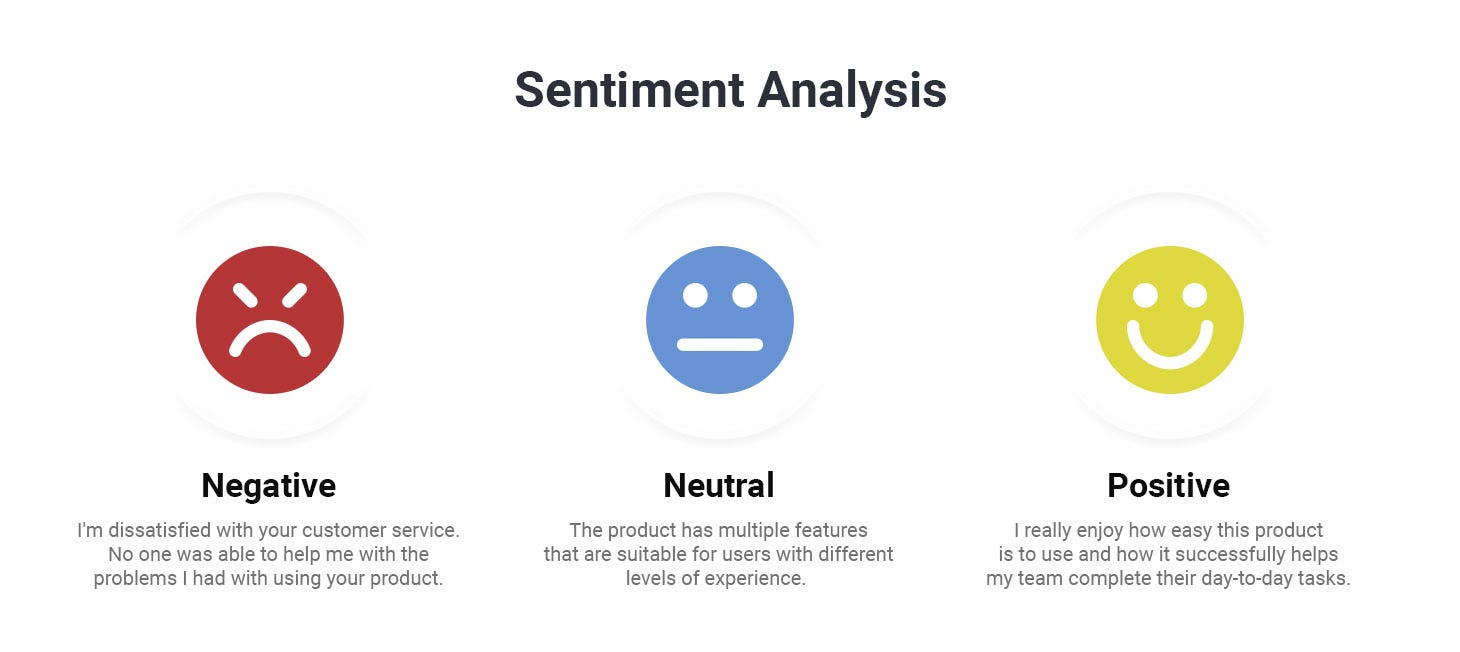

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [2]:
data = pd.read_csv(DATA / 'DisneylandReviews.csv', encoding='latin-1')
print('Reviews:',len(data))
display(data.head())

Reviews: 42656


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very simil...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only st...",Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid when I was visiting the park otherwise i...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortunately there is quite a bit of maintenan...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1 hour from Kowlon, my kids like disneyla...",Disneyland_HongKong


In [3]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [4]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [5]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you'll find Disneyland Hong Kong very simil...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,"Its been a while since d last time we visit HK Disneyland .. Yet, this time we only st...",Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid when I was visiting the park otherwise i...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortunately there is quite a bit of maintenan...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1 hour from Kowlon, my kids like disneyla...",Disneyland_HongKong,positive


In [6]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youll find disneyland hong kong very similar...,positive
1,its been a while since d last time we visit hk disneyland yet this time we only stay i...,positive
2,thanks god it wasn t too hot or too humid when i was visiting the park otherwise it wo...,positive
3,hk disneyland is a great compact park unfortunately there is quite a bit of maintenanc...,positive
4,the location is not in the city took around hour from kowlon my kids like disneyland s...,positive


In [7]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42, stratify=data['Sentiment'])


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [8]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [9]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = LinearSVC(random_state=42, max_iter=5000)
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions, zero_division=0))

Accuracy: 0.85
Classification Report:
              precision    recall  f1-score   support

    negative       0.61      0.59      0.60       725
     neutral       0.46      0.17      0.25      1022
    positive       0.89      0.97      0.93      6785

    accuracy                           0.85      8532
   macro avg       0.65      0.58      0.59      8532
weighted avg       0.81      0.85      0.82      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

Original rows: 413840


Usable, nonconflicting unique reviews: 151989


,Reviews,clean_text,Sentiment
0,"I feel so LUCKY to have found this used (phone to us & not used hard at all), phone on...",feel lucky found used phone u not used hard phone line someone upgraded sold one son l...,positive
1,"nice phone, nice up grade from my pantach revue. Very clean set up and easy set up. ne...",nice phone nice grade pantach revue clean set easy set never android phone fantastic s...,positive
3,It works good but it goes slow sometimes but its a very good phone I love it,work good go slow sometimes good phone love,positive
4,Great phone to replace my lost phone. The only thing is the volume up button does not ...,great phone replace lost phone thing volume button not work still go setting adjust jo...,positive
5,"I already had a phone with problems... I know it stated it was used, but dang, it did ...",already phone problem know stated used dang not state not charge wish would read comme...,negative


Train/test: 121591 30398
Accuracy: 0.8334


              precision    recall  f1-score   support

    negative       0.78      0.84      0.81      8632
     neutral       0.41      0.05      0.08      2776
    positive       0.86      0.95      0.90     18990

    accuracy                           0.83     30398
   macro avg       0.68      0.61      0.60     30398
weighted avg       0.80      0.83      0.80     30398



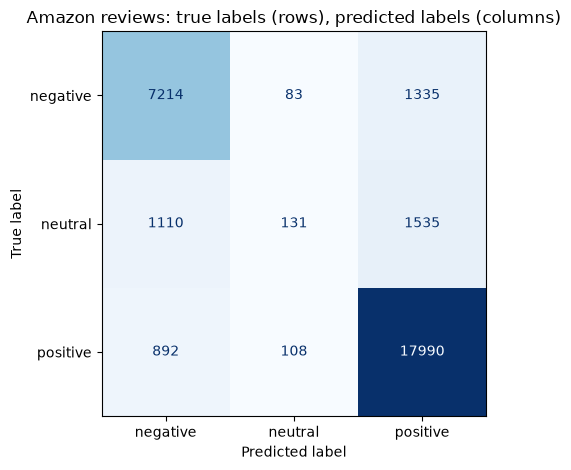

In [10]:
import html, unicodedata
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import nltk
for resource in ['stopwords','wordnet','omw-1.4']:
    nltk.download(resource,quiet=True)

amazon = pd.read_csv(DATA / 'Amazon_Unlocked_Mobile.csv', low_memory=False)
print('Original rows:',len(amazon))
amazon = amazon.dropna(subset=['Reviews','Rating']).copy()
amazon['Rating'] = pd.to_numeric(amazon['Rating'],errors='coerce')
amazon = amazon[amazon['Rating'].between(1,5)].copy()
amazon['Sentiment'] = np.select([amazon.Rating>3,amazon.Rating<3],
                               ['positive','negative'],default='neutral')
stop = set(stopwords.words('english')) - {'no','nor','not','never'}
lemma = WordNetLemmatizer()
def preprocess_review(text):
    # 1. Decode HTML entities and remove HTML markup.
    text = re.sub(r'<[^>]+>', ' ', html.unescape(str(text)))
    # 2. Unicode normalization and lowercasing.
    text = unicodedata.normalize('NFKC',text).lower()
    # 3. Remove URLs.
    text = re.sub(r'https?://\S+|www\.\S+', ' ',text)
    # 4. Expand common negative contractions; remove nonletter symbols.
    text = text.replace("can't",'can not').replace("won't",'will not')
    text = re.sub(r"n['’]t\b",' not',text)
    text = re.sub(r'[^a-z\s]',' ',text)
    # 5. Tokenize, remove stopwords but preserve negation.
    tokens = [w for w in text.split() if w not in stop]
    # 6. Lemmatize and join; joining normalizes whitespace.
    return ' '.join(lemma.lemmatize(w) for w in tokens)

amazon['clean_text'] = amazon['Reviews'].map(preprocess_review)
amazon = amazon[amazon.clean_text.str.len()>0]
# Deduplicate normalized reviews BEFORE splitting to prevent exact text leakage.
conflicts = amazon.groupby('clean_text')['Sentiment'].nunique()
amazon = amazon[amazon.clean_text.isin(conflicts[conflicts==1].index)]
amazon = amazon.drop_duplicates(subset='clean_text')
print('Usable, nonconflicting unique reviews:',len(amazon))
display(amazon[['Reviews','clean_text','Sentiment']].head())
X_train, X_test, y_train, y_test = train_test_split(
    amazon.clean_text,amazon.Sentiment,test_size=0.2,random_state=42,
    stratify=amazon.Sentiment)
vectorizer = TfidfVectorizer(max_features=30000,ngram_range=(1,2),min_df=2)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
classifier = MultinomialNB(alpha=0.5)
classifier.fit(X_train_vec,y_train)
pred = classifier.predict(X_test_vec)
print('Train/test:',len(X_train),len(X_test))
print('Accuracy:',round(accuracy_score(y_test,pred),4))
print(classification_report(y_test,pred,zero_division=0))
labels = ['negative','neutral','positive']
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=labels,
    cmap='Blues',colorbar=False)
plt.title('Amazon reviews: true labels (rows), predicted labels (columns)')
plt.tight_layout(); plt.show()

### Evaluation notes
The Amazon solution implements all six requested tasks. TF-IDF is fitted only on training reviews. Neutral is a genuine third class (rating 3); class-specific precision, recall, F1 and the confusion matrix reveal errors hidden by overall accuracy. Removing duplicate and conflicting review texts reduces leakage, although the random split does not test transfer to entirely unseen phone models. The Disneyland demonstration uses `LinearSVC` for an efficient linear SVM.